# NearMiss — Highway Lane-Change Prediction
CSE3141 · Predictive Analytics · Manipal University Jaipur

**Research question:** From a vehicle’s current state and nearby traffic, will its recorded lane ID change to an adjacent lane during the next two seconds?

We use the public Automatum Full Highway drone trajectories. Labels come from recorded future lane IDs. We compare only the course classifiers: Logistic Regression, LDA and QDA. A prediction describes observed driver behavior; it does not recommend a maneuver or predict a verified crash. The animated simulator remains a separate, rule-programmed experiment.

In [1]:
from pathlib import Path
from contextlib import nullcontext
import csv, gzip, hashlib, json, math, os, time, zipfile
import ijson
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, average_precision_score, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay)
ROOT=Path.cwd() if Path('backend').exists() else Path.cwd().parent
ARCHIVE=ROOT/'data/raw/automatum/automatum_data_full_highway_drone_dataset.zip'
CACHE=ROOT/'data/processed/automatum_lane_change_samples_v2.csv.gz'
OUT=ROOT/'backend/artifacts'; PUBLIC=ROOT/'frontend/public/data'
MANIFEST=ROOT/'data/raw/automatum/download_manifest.json'
for folder in [CACHE.parent,OUT,PUBLIC]: folder.mkdir(parents=True,exist_ok=True)
FEATURES=['speed','acceleration','lateral_speed','front_gap','closing_speed','has_leader',
 'left_front_gap','left_front_closing_speed','left_front_present',
 'left_rear_gap','left_rear_closing_speed','left_rear_present',
 'right_front_gap','right_front_closing_speed','right_front_present',
 'right_rear_gap','right_rear_closing_speed','right_rear_present','is_truck']
TASK='lane-change-behavior'; VERSION='behavior-3'
sns.set_theme(style='whitegrid')
assert ARCHIVE.exists(), f'Download the public dataset first: {ARCHIVE}'
manifest=json.loads(MANIFEST.read_text(encoding='utf-8'))
assert manifest['checksum_verified'] and manifest['zip_crc_verified']
print('Archive SHA-256:',manifest['sha256'],'; recordings:',manifest['trajectory_files'])

Archive SHA-256: 1a562db9c980e535d3f5fd1e1721c96d91390c996a5d57cf07969619629a6681 ; recordings: 114


## 1. Dataset, provenance and access

Automatum publishes 114 highway recordings. Each provides UTM position, vehicle-frame longitudinal and lateral velocity, acceleration, lane and road IDs, heading, vehicle dimensions, and per-frame front/rear relationships in the ego, left and right lanes. Files are read directly from the verified ZIP; the expanded collection is not copied to disk.

Dataset and terms: https://huggingface.co/datasets/AutomatumData/automatum-data-full-highway (CC BY-ND 4.0). Dataset method: Spannaus, Zechel and Lenz, IEEE Intelligent Vehicles Symposium, 2021, AUTOMATUM DATA. Public exports contain aggregate summaries and fitted model parameters, not sampled vehicle rows or track positions. The optional trajectory replay is written only to the ignored local `data/processed` folder.

The recordings are German Autobahn traffic. Model performance must be reported on entire recordings held out from training. This provides a more useful generalization check than randomly splitting frames from the same recorded traffic.

## 2. Stream the recordings and build labeled examples

This preparation cell reads one recording at a time. It stores one-second assessment points while labels are checked on the original frame-rate trajectories. Each positive label means at least one observed adjacent lane-ID transition in the following complete two seconds. Incomplete windows, lane-zero/divider states, road transitions and nonadjacent lane jumps are excluded. No collision proxy or safety threshold creates the target.

Feature selection and engineering keep current longitudinal speed, acceleration, vehicle-frame lateral velocity (`vy_vec`), vehicle type, the front-leader gap, and front/rear gaps and relative speeds in both neighboring lanes. Neighbor distances are projected onto the ego vehicle's current heading so rotated road segments are handled correctly. Missing neighbors receive explicit presence flags and a documented capped-gap encoding. Vehicle IDs, recording names, coordinates and future labels are excluded as model inputs.

In [2]:
def nearest_indices(times, targets):
    right=np.searchsorted(times,targets).clip(0,len(times)-1)
    left=(right-1).clip(0,len(times)-1)
    return np.where(np.abs(times[left]-targets)<=np.abs(times[right]-targets),left,right)

def vector(obj,key,dtype=np.float64):
    try: return np.asarray(obj.get(key,[]),dtype=dtype)
    except (TypeError,ValueError): return np.asarray([],dtype=dtype)

def state_arrays(obj, seconds, idx):
    good=(np.abs(vector(obj,'time')[idx]-seconds)<=0.5/29.97+0.004)
    ix=idx[good]
    if not len(ix): return None
    return dict(seconds=seconds[good].astype(np.int32),x=vector(obj,'x_vec')[ix].astype(np.float32),
        y=vector(obj,'y_vec')[ix].astype(np.float32),vx=vector(obj,'vx_vec')[ix].astype(np.float32),
        psi=vector(obj,'psi_vec')[ix].astype(np.float32),
        lane=vector(obj,'lane_id_vec',np.int32)[ix],road=vector(obj,'road_id_vec',np.int32)[ix],
        length=np.full(len(ix),float(obj.get('length',4.6)),dtype=np.float32),
        width=np.full(len(ix),float(obj.get('width',1.8)),dtype=np.float32))

def nearby_state(states,identity,second,ego_lane,ego_road,role):
    other=states.get(identity)
    if other is None: return None
    j=int(np.searchsorted(other['seconds'],int(second)))
    if j>=len(other['seconds']) or other['seconds'][j]!=int(second): return None
    lane=int(other['lane'][j])
    if int(other['road'][j])!=int(ego_road) or lane==0 or np.sign(lane)!=np.sign(ego_lane): return None
    if role=='front' and abs(lane)!=abs(ego_lane): return None
    if role in ('left','right') and abs(abs(lane)-abs(ego_lane))!=1: return None
    return other,j

def gap_and_closing(states,identity,second,ego,ego_lane,ego_road,role,kind):
    if not identity: return 150.0,0.0,0
    found=nearby_state(states,identity,second,ego_lane,ego_road,role)
    if found is None: return 150.0,0.0,0
    other,j=found
    dx=float(other['x'][j])-float(ego['x']);dy=float(other['y'][j])-float(ego['y'])
    longitudinal=dx*math.cos(float(ego['psi']))+dy*math.sin(float(ego['psi']))
    directed=longitudinal if kind=='front' else -longitudinal
    distance=max(0.0,directed-0.5*(float(ego['length'])+float(other['length'][j])))
    ego_speed=abs(float(ego['vx'])); other_speed=abs(float(other['vx'][j]))
    closing=ego_speed-other_speed if kind=='front' else other_speed-ego_speed
    return min(150.0,distance),closing,1

def add_recording(member,record_id,writer,archive,summary):
    started=time.monotonic(); states={}; total_frames=0; transitions=0; vehicle_count=0
    recording_start=float('inf');recording_end=float('-inf')
    temp=CACHE.parent/f'.{record_id.replace("/","_")}.base.jsonl.gz'
    with archive.open(member) as stream, gzip.open(temp,'wt',encoding='utf-8',compresslevel=1) as spool:
        for obj in ijson.items(stream,'objects.item'):
            vehicle_count+=1
            required=['time','x_vec','y_vec','vx_vec','vy_vec','ax_vec','psi_vec','lane_id_vec','road_id_vec']
            arrays={key:vector(obj,key,np.int32 if key in ['lane_id_vec','road_id_vec'] else np.float64) for key in required}
            n=min((len(value) for value in arrays.values()),default=0)
            if n<5: continue
            arrays={key:value[:n] for key,value in arrays.items()}; t=arrays['time']
            if not np.all(np.diff(t)>0): continue
            total_frames+=n; lane=arrays['lane_id_vec']; road=arrays['road_id_vec']
            recording_start=min(recording_start,float(t[0]));recording_end=max(recording_end,float(t[-1]))
            same_road=road[1:]==road[:-1]; lane_diff=np.abs(np.diff(lane))
            adjacent=(lane_diff==1)&same_road&(lane[:-1]!=0)&(lane[1:]!=0)&(np.sign(lane[:-1])==np.sign(lane[1:]))
            transitions+=int(np.sum(adjacent))
            seconds=np.arange(math.ceil(t[0]),math.floor(t[-1])+1,dtype=np.int32)
            if not len(seconds): continue
            sampled_idx=nearest_indices(t,seconds)
            sampled=state_arrays(obj,seconds,sampled_idx)
            if sampled is None: continue
            states[str(obj.get('UUID',''))]=sampled

            # Keep current samples only when the complete two-second future is observed.
            candidate_seconds=np.arange(max(math.ceil(t[0]),int(seconds[0])),
                min(math.floor(t[-1]-2.0),int(seconds[-1]))+1,dtype=np.int32)
            if not len(candidate_seconds): continue
            current=nearest_indices(t,candidate_seconds)
            future=nearest_indices(t,candidate_seconds.astype(float)+2.0)
            tolerance=0.5/29.97+0.004
            valid=(np.abs(t[current]-candidate_seconds)<=tolerance)&(np.abs(t[future]-(candidate_seconds+2))<=tolerance)
            valid &= (lane[current]!=0)&(lane[future]!=0)&(road[future]==road[current])
            gap_bad=np.r_[0,np.cumsum(np.diff(t)>0.12)]
            lane_zero=np.r_[0,np.cumsum(lane[1:]==0)]
            road_change=np.r_[0,np.cumsum(road[1:]!=road[:-1])]
            nonadjacent=np.r_[0,np.cumsum(lane_diff>1)]
            crosses=np.r_[0,np.cumsum(adjacent)]
            valid &= (gap_bad[future]-gap_bad[current]==0)&(lane_zero[future]-lane_zero[current]==0)
            valid &= (road_change[future]-road_change[current]==0)&(nonadjacent[future]-nonadjacent[current]==0)
            labels=(crosses[future]-crosses[current]>0).astype(np.uint8)
            relation=obj.get('object_relation_dict_list',[])
            for k in np.flatnonzero(valid):
                i=int(current[k]); sec=int(candidate_seconds[k])
                if i>=len(relation): rel={}
                else: rel=relation[i] or {}
                base=dict(vehicle_id=str(obj.get('UUID','')),second=sec,target=int(labels[k]),
                    lane=int(lane[i]),road=int(road[i]),x=float(arrays['x_vec'][i]),y=float(arrays['y_vec'][i]),
                    speed=abs(float(arrays['vx_vec'][i])),acceleration=float(arrays['ax_vec'][i]),
                    lateral_speed=abs(float(arrays['vy_vec'][i])),length=float(obj.get('length',4.6)),width=float(obj.get('width',1.8)),
                    is_truck=int('truck' in str(obj.get('objType','')).lower()),relations=rel)
                spool.write(json.dumps(base,separators=(',',':'))+'\n')

    # Join the saved relationship IDs to measured vehicles at the same second.
    examples=0; unresolved=0
    with gzip.open(temp,'rt',encoding='utf-8') as spool:
        for line in spool:
            row=json.loads(line); ego_state=states.get(row['vehicle_id'])
            if ego_state is None: continue
            j=int(np.searchsorted(ego_state['seconds'],row['second']))
            if j>=len(ego_state['seconds']) or int(ego_state['seconds'][j])!=row['second']: continue
            ego=dict(x=row['x'],y=row['y'],psi=float(ego_state['psi'][j]),vx=row['speed'],lane=row['lane'],road=row['road'],length=row['length'])
            rel=row['relations']; inputs={'speed':row['speed'],'acceleration':row['acceleration'],
                'lateral_speed':row['lateral_speed'],'is_truck':row['is_truck']}
            fg,fc,fh=gap_and_closing(states,rel.get('front_ego'),row['second'],ego,row['lane'],row['road'],'front','front')
            inputs.update(front_gap=fg,closing_speed=fc,has_leader=fh)
            for side,role in [('left','left'),('right','right')]:
                for position,kind in [('front','front'),('rear','rear')]:
                    relation_key=f'{position}_{role}' if position=='front' else f'behind_{role}'
                    gap,closing,present=gap_and_closing(states,rel.get(relation_key),row['second'],ego,row['lane'],row['road'],role,kind)
                    inputs[f'{side}_{position}_gap']=gap
                    inputs[f'{side}_{position}_closing_speed']=closing
                    inputs[f'{side}_{position}_present']=present
            unresolved+=int(bool(rel.get('front_ego')) and not inputs['has_leader'])
            writer.writerow([inputs[name] for name in FEATURES]+[row['target'],record_id,row['vehicle_id'],row['second'],row['lane'],row['road'],row['x'],row['y'],row['length'],row['width'],row['is_truck']])
            examples+=1
    temp.unlink(missing_ok=True)

    summary.append(dict(recording=record_id,vehicles=vehicle_count,raw_observations=total_frames,
        duration_seconds=max(0.0,recording_end-recording_start) if np.isfinite(recording_start) else 0.0,
        lane_crossings=transitions,eligible_windows=examples,unresolved_front_references=unresolved,
        processing_seconds=round(time.monotonic()-started,1)))
    print(f'{record_id}: {vehicle_count:,} vehicles, {examples:,} windows, {transitions:,} lane crossings',flush=True)

if not CACHE.exists():
    assert len(manifest.get('recording_folders',[]))==114
    with zipfile.ZipFile(ARCHIVE) as archive:
        members=sorted(n for n in archive.namelist() if n.endswith('/dynamicWorld.json'))
        assert len(members)==114
        tmp_cache=CACHE.with_suffix('.partial.gz');summary=[]
        columns=FEATURES+['target','recording','vehicle_id','second','lane_id','road_id','x','y','length','width','vehicle_is_truck']
        with gzip.open(tmp_cache,'wt',encoding='utf-8',newline='',compresslevel=1) as output:
            writer=csv.writer(output);writer.writerow(columns)
            for member in members:
                record_id=str(Path(member).parent)
                add_recording(member,record_id,writer,archive,summary)
        os.replace(tmp_cache,CACHE)
    detail=dict(task=TASK,version=VERSION,source='Automatum Full Highway Drone Dataset',
        source_url='https://huggingface.co/datasets/AutomatumData/automatum-data-full-highway',
        archive_sha256=manifest['sha256'],recordings=summary)
    (CACHE.parent/'automatum_processing.json').write_text(json.dumps(detail,indent=2),encoding='utf-8')
else:
    detail=json.loads((CACHE.parent/'automatum_processing.json').read_text(encoding='utf-8'))
    summary=detail['recordings']
print('Processed sample cache:',CACHE,'size MB',round(CACHE.stat().st_size/1e6,1))

Processed sample cache: C:\Users\USER\predictive-analytics\data\processed\automatum_lane_change_samples_v2.csv.gz size MB 111.2


In [3]:
dtypes={name:'float32' for name in FEATURES};dtypes.update(target='uint8',recording='category',vehicle_id='category',second='int32',lane_id='int8',road_id='int16',x='float32',y='float32',length='float32',width='float32',vehicle_is_truck='uint8')
df=pd.read_csv(CACHE,dtype=dtypes)
clean_columns=FEATURES+['target','recording','vehicle_id']
missing_before=df[clean_columns].replace([np.inf,-np.inf],np.nan).isna()
missing_cells_before=int(missing_before.sum().sum());missing_rows_dropped=int(missing_before.any(axis=1).sum())
df=df.replace([np.inf,-np.inf],np.nan).dropna(subset=clean_columns).reset_index(drop=True)
recordings=sorted(df.recording.unique().tolist())
print('Eligible windows:',len(df),'recordings:',len(recordings),'vehicles:',df.vehicle_id.nunique())
print('Stay/change windows:',df.target.value_counts().sort_index().to_dict())
print('Recorded crossings:',sum(s['lane_crossings'] for s in summary))
display(df[FEATURES+['target']].describe().T[['mean','std','min','max']])

Eligible windows: 679705 recordings: 114 vehicles: 114638
Stay/change windows: {0: 651059, 1: 28646}
Recorded crossings: 20193


,mean,std,min,max
speed,32.644920,7.865221,0.049216,75.818260
acceleration,-0.002004,0.280584,-3.811527,3.704510
lateral_speed,0.001026,0.011655,0.000000,9.483171
front_gap,104.599213,49.603859,0.084985,150.000000
closing_speed,-0.106298,3.499818,-40.456081,40.309887
has_leader,0.590899,0.491668,0.000000,1.000000
left_front_gap,106.952835,56.797623,0.000000,150.000000
left_front_closing_speed,-3.476924,5.548192,-46.699837,25.303610
left_front_present,0.453553,0.497838,0.000000,1.000000
left_rear_gap,111.468124,56.865166,0.000000,150.000000


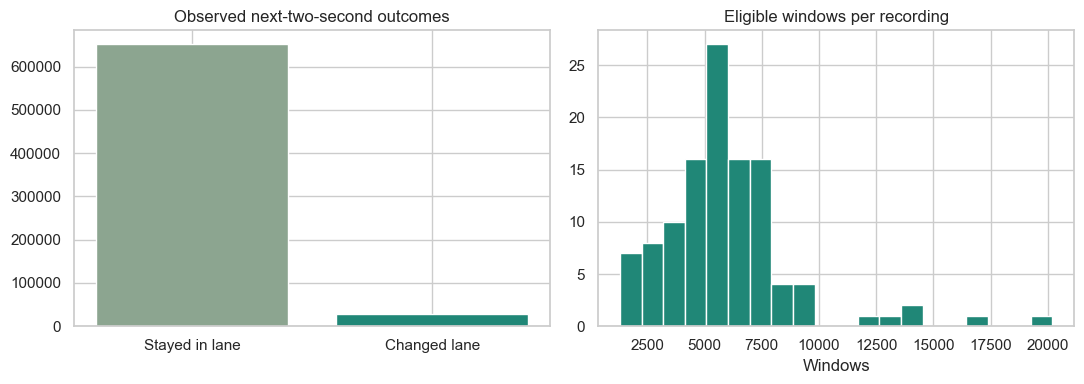

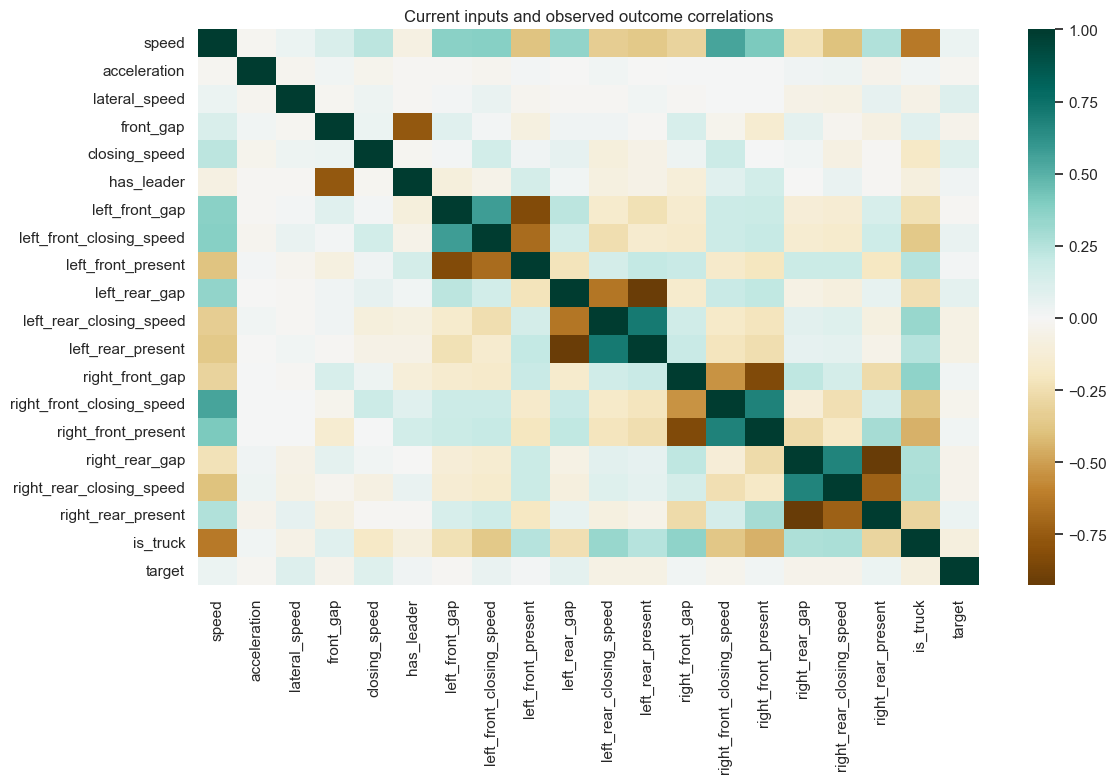

In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
counts=df.target.value_counts().reindex([0,1],fill_value=0)
axes[0].bar(['Stayed in lane','Changed lane'],counts.values,color=['#8ca590','#208777'])
axes[0].set_title('Observed next-two-second outcomes')
class_counts=df.groupby('recording',observed=True).target.agg(['count','sum'])
axes[1].hist(class_counts['count'],bins=20,color='#208777');axes[1].set_title('Eligible windows per recording');axes[1].set_xlabel('Windows')
plt.tight_layout();plt.show()
sample=df.sample(min(20000,len(df)),random_state=42)
fig,ax=plt.subplots(figsize=(12,8));sns.heatmap(sample[FEATURES+['target']].corr(),cmap='BrBG',center=0,ax=ax);plt.title('Current inputs and observed outcome correlations');plt.tight_layout();plt.show()

## 3. Data checks and exploratory analysis

The summary reports missing values, repeated keys, descriptive statistics, and IQR outliers. IQR flags are inspected; real braking and lateral movement are not automatically deleted just because they are unusual. Eligibility is based on whether the current state and full future window exist. Positive windows near one maneuver can overlap, so they are not unique lane-change counts.

Missing or non-finite model-field cells before cleaning: 0
Rows removed for a missing/non-finite model field: 0
Missing model-field cells after cleaning: 0
Duplicate vehicle-second examples: 0


,feature,q1,q3,iqr_outlier_count
0,speed,24.923254,37.752464,2693
1,acceleration,-0.099608,0.113355,72075
2,lateral_speed,0.000125,0.001057,79247
3,front_gap,55.124596,150.000000,0
4,closing_speed,-0.434291,0.313050,215723
5,has_leader,0.000000,1.000000,0
6,left_front_gap,50.062241,150.000000,0
7,left_front_closing_speed,-6.561337,0.000000,23664
8,left_front_present,0.000000,1.000000,0
9,left_rear_gap,54.956440,150.000000,0


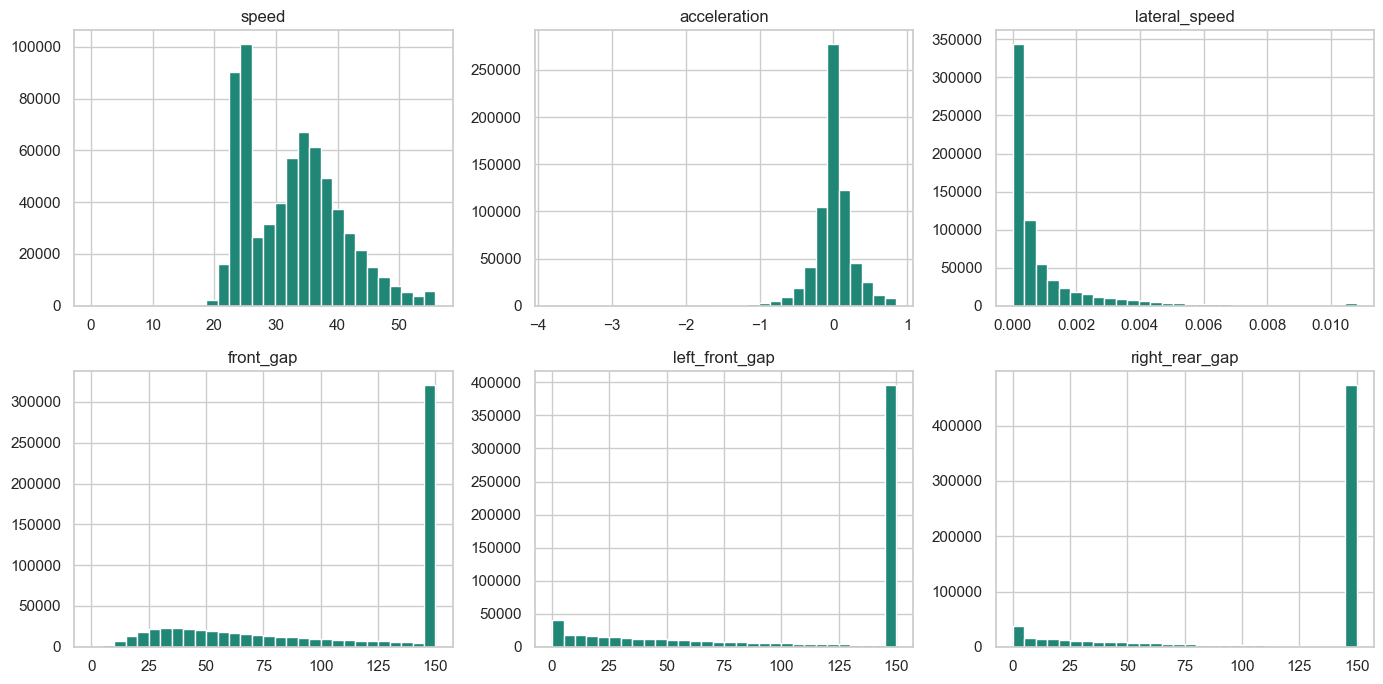

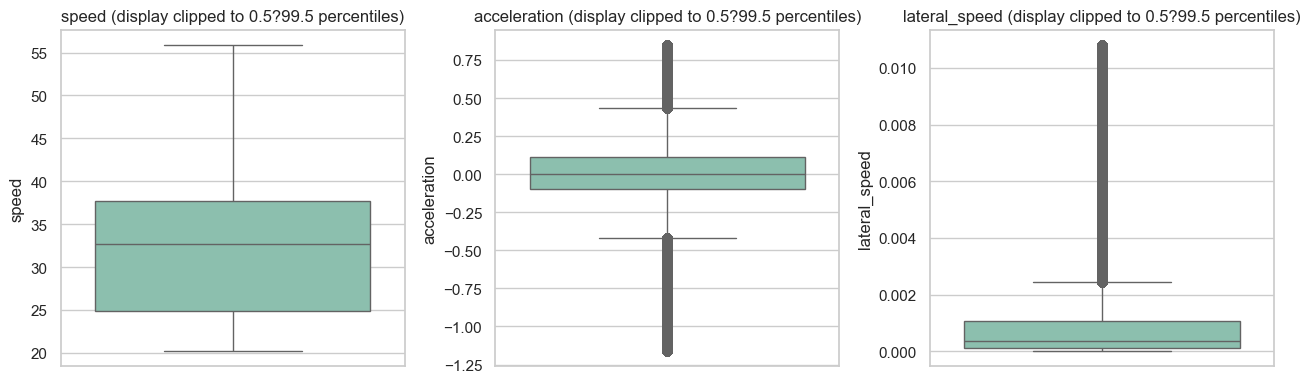

In [5]:
print('Missing or non-finite model-field cells before cleaning:',missing_cells_before)
print('Rows removed for a missing/non-finite model field:',missing_rows_dropped)
print('Missing model-field cells after cleaning:',int(df[FEATURES+['target']].isna().sum().sum()))
print('Duplicate vehicle-second examples:',int(df.duplicated(['recording','vehicle_id','second']).sum()))
iqr_rows=[]
for feature in FEATURES:
    q1,q3=df[feature].quantile([.25,.75]);iqr=q3-q1
    iqr_rows.append(dict(feature=feature,q1=q1,q3=q3,iqr_outlier_count=int(((df[feature]<q1-1.5*iqr)|(df[feature]>q3+1.5*iqr)).sum())))
display(pd.DataFrame(iqr_rows))
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,feature in zip(axes.flat,['speed','acceleration','lateral_speed','front_gap','left_front_gap','right_rear_gap']):
    ax.hist(df[feature].clip(upper=df[feature].quantile(.995)),bins=30,color='#208777');ax.set_title(feature)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,feature in zip(axes,['speed','acceleration','lateral_speed']):
    sns.boxplot(y=df[feature].clip(lower=df[feature].quantile(.005),upper=df[feature].quantile(.995)),ax=ax,color='#83c8b1')
    ax.set_title(f'{feature} (display clipped to 0.5?99.5 percentiles)')
plt.tight_layout();plt.show()

## 4. Split by whole recording

Random frame splits can put the same road scene and vehicle trajectories in training and test data. Instead, randomly assign entire recordings to 60% training, 20% validation and 20% test. Then tune with grouped cross-validation over training recordings only. The final test recordings remain untouched until model and cutoff selection are complete.

In [6]:
rng=np.random.default_rng(3141);group_order=np.asarray(recordings,dtype=object);rng.shuffle(group_order)
n_train=int(.6*len(group_order));n_validation=int(.2*len(group_order))
train_recordings=set(group_order[:n_train]);validation_recordings=set(group_order[n_train:n_train+n_validation]);test_recordings=set(group_order[n_train+n_validation:])
train_mask=df.recording.isin(train_recordings).to_numpy();validation_mask=df.recording.isin(validation_recordings).to_numpy();test_mask=df.recording.isin(test_recordings).to_numpy()
train=df.loc[train_mask];validation=df.loc[validation_mask];test=df.loc[test_mask]
assert not train_recordings&validation_recordings and not train_recordings&test_recordings and not validation_recordings&test_recordings
assert train.target.nunique()==validation.target.nunique()==test.target.nunique()==2
print('Recordings:',len(train_recordings),len(validation_recordings),len(test_recordings))
for name,part in [('train',train),('validation',validation),('test',test)]:print(name,len(part),part.target.value_counts().to_dict(), 'rate',round(float(part.target.mean()),5))
X_train=train[FEATURES];y_train=train.target.astype(int)
groups=train.recording.astype(str).to_numpy();cv=GroupKFold(n_splits=3)
cv_splits=list(cv.split(X_train,y_train,groups=groups))
print('Grouped CV fold sizes:',[(len(a),len(b)) for a,b in cv_splits])

Recordings: 68 22 24
train 406853 {0: 389815, 1: 17038} rate 0.04188
validation 143985 {0: 136756, 1: 7229} rate 0.05021
test 128867 {0: 124488, 1: 4379} rate 0.03398


Grouped CV fold sizes: [(272020, 134833), (270825, 136028), (270861, 135992)]


## 5. Compare the three course classifiers

Scaling is fitted inside each training fold. Grouped CV holds out whole recordings. Grid search compares reasonable settings for Logistic Regression, LDA and QDA. Because lane changes are rarer than staying in lane, the notebook reports precision, recall, F1, ROC-AUC, average precision, balanced accuracy and the always-stay baseline. Accuracy alone can hide missed lane changes.

In [7]:
def evaluate(model,part,threshold=.5):
    probability=model.predict_proba(part[FEATURES])[:,list(model.classes_).index(1)]
    prediction=(probability>=threshold).astype(int)
    return dict(accuracy=float(accuracy_score(part.target,prediction)),precision=float(precision_score(part.target,prediction,zero_division=0)),
        recall=float(recall_score(part.target,prediction,zero_division=0)),f1=float(f1_score(part.target,prediction,zero_division=0)),
        roc_auc=float(roc_auc_score(part.target,probability)),average_precision=float(average_precision_score(part.target,probability)),
        balanced_accuracy=float(balanced_accuracy_score(part.target,prediction)),confusion_matrix=confusion_matrix(part.target,prediction).tolist())

specifications=[('Logistic Regression',LogisticRegression(max_iter=1500,random_state=42),
    {'model__C':[.1,1,10],'model__class_weight':[None,'balanced']}),
    ('LDA',LinearDiscriminantAnalysis(solver='lsqr'),
     {'model__shrinkage':['auto',.1,.5],'model__priors':[None,[.5,.5]]}),
    ('QDA',QuadraticDiscriminantAnalysis(),
     {'model__reg_param':[.1,.5,.9],'model__priors':[None,[.5,.5]]})]
models={};results=[]
for name,classifier,grid in specifications:
    search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',classifier)]),grid,cv=cv_splits,scoring='f1',n_jobs=1,pre_dispatch=1,error_score='raise')
    search.fit(X_train,y_train);model=search.best_estimator_;models[name]=model
    probabilities=model.predict_proba(validation[FEATURES])[:,list(model.classes_).index(1)]
    thresholds=[.05,.1,.15,.2,.3,.4,.5,.6,.7,.8]
    cutoff=max(thresholds,key=lambda t:(f1_score(validation.target,(probabilities>=t).astype(int),zero_division=0),precision_score(validation.target,(probabilities>=t).astype(int),zero_division=0),t))
    results.append(dict(name=name,cv_f1=float(search.best_score_),parameters=search.best_params_,threshold=float(cutoff),
        validation=evaluate(model,validation,cutoff),training=evaluate(model,train,cutoff)))
    print(name,'best parameters:',search.best_params_,'CV F1:',round(search.best_score_,4),'validation F1:',round(results[-1]['validation']['f1'],4))
display(pd.DataFrame([dict(model=r['name'],cv_f1=r['cv_f1'],validation_f1=r['validation']['f1'],validation_precision=r['validation']['precision'],validation_recall=r['validation']['recall'],validation_ap=r['validation']['average_precision'],cutoff=r['threshold']) for r in results]))

Logistic Regression best parameters: {'model__C': 1, 'model__class_weight': 'balanced'} CV F1: 0.1664 validation F1: 0.2276


LDA best parameters: {'model__priors': [0.5, 0.5], 'model__shrinkage': 'auto'} CV F1: 0.158 validation F1: 0.2113


QDA best parameters: {'model__priors': None, 'model__reg_param': 0.1} CV F1: 0.2287 validation F1: 0.2561


,model,cv_f1,validation_f1,validation_precision,validation_recall,validation_ap,cutoff
0,Logistic Regression,0.166412,0.227642,0.165048,0.366717,0.158032,0.7
1,LDA,0.158032,0.211258,0.153973,0.336423,0.139001,0.7
2,QDA,0.228673,0.256136,0.185507,0.413612,0.162929,0.4


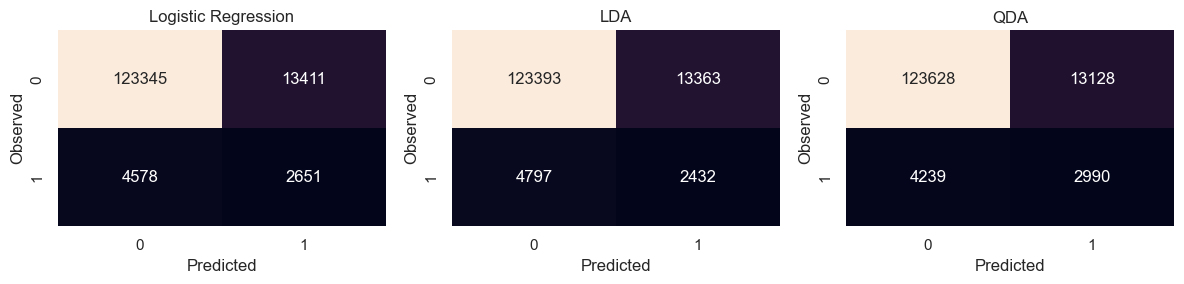

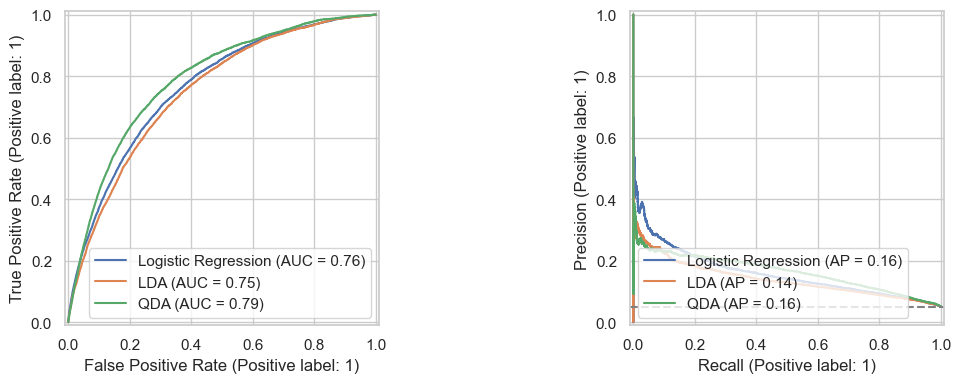

In [8]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,result in zip(axes,results):
    sns.heatmap(result['validation']['confusion_matrix'],annot=True,fmt='d',cbar=False,ax=ax);ax.set_title(result['name']);ax.set_xlabel('Predicted');ax.set_ylabel('Observed')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,model in models.items():
    RocCurveDisplay.from_estimator(model,validation[FEATURES],validation.target,ax=axes[0],name=name)
    PrecisionRecallDisplay.from_estimator(model,validation[FEATURES],validation.target,ax=axes[1],name=name)
axes[1].axhline(validation.target.mean(),linestyle='--',color='gray',label='Positive prevalence')
plt.tight_layout();plt.show()

## 6. Select on validation and evaluate the held-out recordings

Choose the classifier using validation F1, then average precision and ROC-AUC as tie-breakers. The decision cutoff is selected on validation. Evaluate exactly once on the separate test recordings. Compare with predicting “stay in lane” for every case; this baseline often looks strong on accuracy because lane changes are uncommon.

In [9]:
winner=max(results,key=lambda r:(r['validation']['f1'],r['validation']['average_precision'],r['validation']['roc_auc']))
selected=models[winner['name']];test_metrics=evaluate(selected,test,winner['threshold'])
test_probability=selected.predict_proba(test[FEATURES])[:,list(selected.classes_).index(1)]
test_prediction=(test_probability>=winner['threshold']).astype(int)
baseline=dict(name='Always stay in lane',accuracy=float((test.target==0).mean()),precision=0.0,recall=0.0,f1=0.0,balanced_accuracy=.5,roc_auc=.5,average_precision=float(test.target.mean()))
print('Selected:',winner['name'],'cutoff:',winner['threshold'])
print('Held-out recordings test metrics:',test_metrics)
print('Always-stay baseline:',baseline)
print('Test recordings:',sorted(test_recordings))

Selected: QDA cutoff: 0.4
Held-out recordings test metrics: {'accuracy': 0.8699123902938689, 'precision': 0.13018811585547924, 'recall': 0.49783055492121486, 'f1': 0.2064003029729218, 'roc_auc': 0.8002821906095305, 'average_precision': 0.12057050510626804, 'balanced_accuracy': 0.6904156630399404, 'confusion_matrix': [[109923, 14565], [2199, 2180]]}
Always-stay baseline: {'name': 'Always stay in lane', 'accuracy': 0.9660192291277053, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'balanced_accuracy': 0.5, 'roc_auc': 0.5, 'average_precision': 0.03398077087229469}
Test recordings: ['hw-a9-appershofen-003-6d6e3378-df9b-4130-8cbf-3437a77a309d', 'hw-a9-appershofen-006-7e386963-33f2-4e71-a750-76cc66791d43', 'hw-a9-appershofen-008-44cb097b-ce86-4d2d-b509-0e0c5b5b7ad5', 'hw-a9-appershofen-009-2caba3d6-ef31-48c8-b8e1-d9c6a300a68a', 'hw-a9-apperszell-010-5a04160f-c961-4d9a-8f78-1dd6cc3956e4', 'hw-a9-denkendorf-002-806f9df5-3599-4f69-94c3-92ee327992e7', 'hw-a9-denkendorf-005-d2c2e9bd-6500-4efd-a451-e

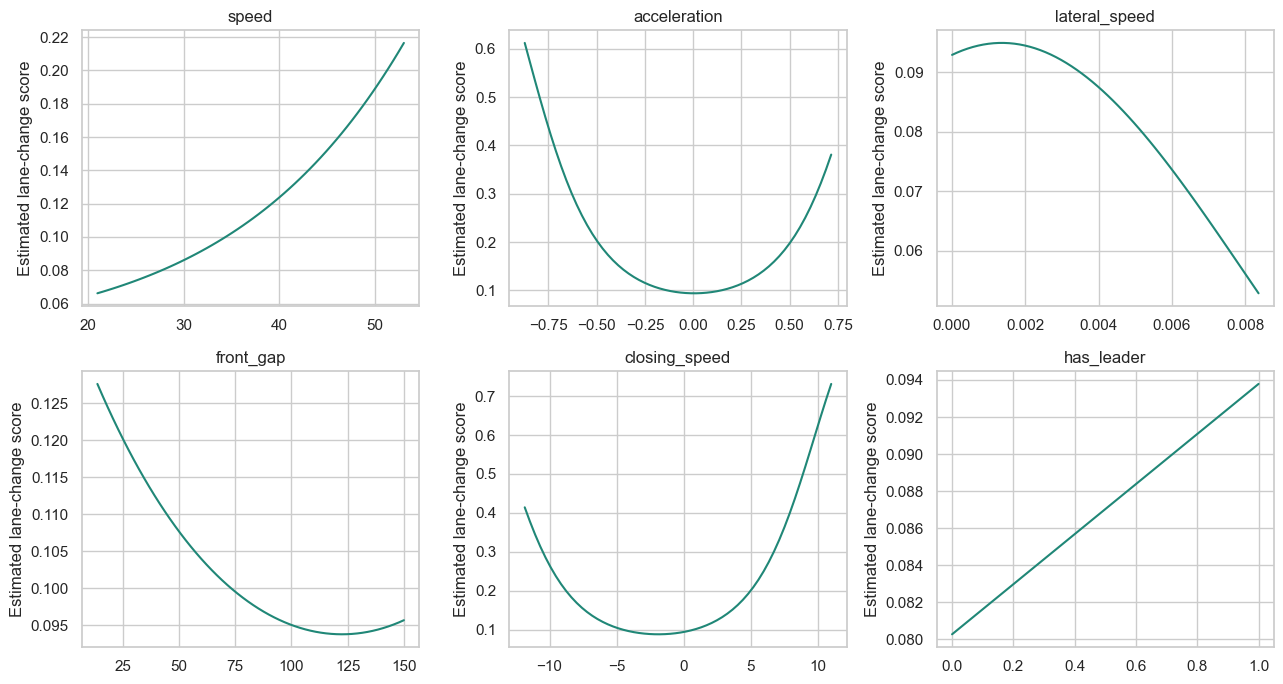

These are fitted associations. Lateral movement can already be underway; the scores are not calibrated safety estimates.


In [10]:
fig,axes=plt.subplots(2,3,figsize=(13,7))
for ax,feature in zip(axes.flat,FEATURES[:6]):
    grid=pd.DataFrame([X_train.median()]*60);grid[feature]=np.linspace(X_train[feature].quantile(.01),X_train[feature].quantile(.99),60)
    if feature.endswith('_present') or feature in ['has_leader','is_truck']:grid[feature]=(grid[feature]>.5).astype(int)
    ax.plot(grid[feature],selected.predict_proba(grid)[:,1],color='#208777');ax.set(title=feature,ylabel='Estimated lane-change score')
plt.tight_layout();plt.show()
print('These are fitted associations. Lateral movement can already be underway; the scores are not calibrated safety estimates.')

## 7. Export the fitted model and measured research results

The backend and browser receive the same training-fitted classifier and validation cutoff. The exported portable parameters allow the front end to calculate the same model score if the API is starting or offline. Raw Automatum files, sampled vehicle rows, track positions and vehicle identifiers stay in local ignored data files; public exports contain aggregate measurements and fitted-model parameters.

In [11]:
scale=selected.named_steps['scale'];classifier=selected.named_steps['model']
portable=dict(mean=scale.mean_.tolist(),scale=scale.scale_.tolist())
if winner['name']=='QDA':
    portable.update(kind='scaled-qda',means=classifier.means_.tolist(),rotations=[r.tolist() for r in classifier.rotations_],variances=[v.tolist() for v in classifier.scalings_],priors=classifier.priors_.tolist())
else:portable.update(kind='scaled-logit',coefficients=classifier.coef_[0].tolist(),intercept=float(classifier.intercept_[0]))
ranges={key:[float(X_train[key].min()),float(X_train[key].max())] for key in FEATURES}
info=dict(task=TASK,version=VERSION,name=winner['name'],features=FEATURES,
  units={key:('m/s vehicle-frame lateral velocity' if key=='lateral_speed' else 'm/s' if 'speed' in key else 'm/s^2' if key=='acceleration' else 'm' if key.endswith('_gap') or key=='front_gap' else '0 or 1') for key in FEATURES},
 ranges=ranges,horizon_seconds=2,labels={'0':'Stay in lane','1':'Lane change'},
 target='Any observed adjacent lane-ID transition within the next complete two seconds on the same road',
 decision_threshold=float(winner['threshold']),browser_model=portable,
 source='Automatum Full Highway Drone Dataset',dataset_url='https://huggingface.co/datasets/AutomatumData/automatum-data-full-highway',
 limitations=['Observed lane-change behavior, not accident probability or lane recommendation','Lateral movement may already have started','Test scores are for held-out recordings from the same dataset, not every country or highway','Probabilities are uncalibrated'])
metrics=dict(task=TASK,version=VERSION,selected_model=winner['name'],comparison=results,test=test_metrics,baseline=baseline,
 split_sizes={'train':int(len(train)),'validation':int(len(validation)),'test':int(len(test))},
 class_counts={name:{str(k):int(v) for k,v in part.target.value_counts().items()} for name,part in [('train',train),('validation',validation),('test',test)]},
 split_recordings={'train':sorted(train_recordings),'validation':sorted(validation_recordings),'test':sorted(test_recordings)},
 protocol='60/20/20 whole-recording group split; three-fold GroupKFold inside training recordings; threshold and model selected on validation; held-out recording test used once')
joblib.dump(selected,OUT/'behavior.joblib')
model_id=hashlib.sha256((OUT/'behavior.joblib').read_bytes()+json.dumps(info,sort_keys=True,separators=(',',':'),allow_nan=False).encode()).hexdigest()
info['model_id']=model_id;metrics['model_id']=model_id
for name,value in [('info',info),('metrics',metrics)]:
    for folder in [OUT,PUBLIC]:(folder/f'{name}.json').write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
print('Exported model and aggregate validation:',winner['name'])

Exported model and aggregate validation: QDA


## 8. Local trajectory replay

For each confusion-matrix outcome, select distinct held-out vehicles. Freeze the model inputs and forecast before reading the two-second future. The notebook saves nearby recorded positions at ten frames per second under ignored `data/processed/automatum_replay_local.json`. This file stays local under the source dataset's NoDerivatives terms. Public performance comes from the aggregate held-out metrics, not published trajectory snippets.

In [12]:
test_rows=test.copy();test_rows['probability']=test_probability;test_rows['predicted']=test_prediction
selected_examples=[];used=set()
for actual,predicted in [(1,1),(1,0),(0,1),(0,0)]:
    candidates=test_rows[(test_rows.target==actual)&(test_rows.predicted==predicted)]
    candidates=candidates.sample(frac=1,random_state=3141+actual*10+predicted)
    for _,row in candidates.iterrows():
        if row.vehicle_id in used:continue
        selected_examples.append(dict(recording=str(row.recording),vehicle_uuid=str(row.vehicle_id),second=int(row.second),
            lane_id=int(row.lane_id),road_id=int(row.road_id),actual=int(actual),predicted=int(predicted),probability=float(row.probability),
            inputs={key:float(row[key]) for key in FEATURES}))
        used.add(row.vehicle_id)
        if sum(e['actual']==actual and e['predicted']==predicted for e in selected_examples)>=4:break
assert {(e['actual'],e['predicted']) for e in selected_examples}=={(0,0),(0,1),(1,0),(1,1)}

def replay_recording(record_id,examples,archive,members):
    member=members[record_id];targets={}
    for e in examples:
        targets[e['vehicle_uuid']]=e
    low=min(e['second'] for e in examples)-.04;high=max(e['second'] for e in examples)+2.04
    tracks=[];id_map={};next_id=1
    with archive.open(member) as stream:
        for obj in ijson.items(stream,'objects.item'):
            t=vector(obj,'time');n=min(len(t),len(obj.get('x_vec',[])),len(obj.get('y_vec',[])),len(obj.get('psi_vec',[])),len(obj.get('lane_id_vec',[])),len(obj.get('road_id_vec',[])),len(obj.get('vx_vec',[])))
            if n<2:continue
            t=t[:n];lo=np.searchsorted(t,low-.06);hi=np.searchsorted(t,high+.06)
            if hi<=lo:continue
            identity=str(obj.get('UUID',''));lane=vector(obj,'lane_id_vec',np.int32)[:n];road=vector(obj,'road_id_vec',np.int32)[:n]
            idx=np.arange(lo,hi);tracks.append(dict(uuid=identity,t=t[idx].astype(np.float32),x=vector(obj,'x_vec')[idx].astype(np.float32),
                y=vector(obj,'y_vec')[idx].astype(np.float32),psi=vector(obj,'psi_vec')[idx].astype(np.float32),vx=vector(obj,'vx_vec')[idx].astype(np.float32),lane=lane[idx],road=road[idx],
                length=float(obj.get('length',4.6)),width=float(obj.get('width',1.8)),truck='truck' in str(obj.get('objType','')).lower()))
            id_map[identity]=next_id;next_id+=1
    for e in examples:e['vehicle_id']=id_map[e['vehicle_uuid']]
    all_times=sorted({round(e['second']+step*.1,3) for e in examples for step in range(21)})
    ego_pose={};car_by_time={t:[] for t in all_times}
    example_by_time={round(e['second']+step*.1,3):(e,step) for e in examples for step in range(21)}
    ego_tracks={e['vehicle_uuid']:next(v for v in tracks if v['uuid']==e['vehicle_uuid']) for e in examples}
    for e in examples:
        track=ego_tracks[e['vehicle_uuid']]
        for step in range(21):
            target=round(e['second']+step*.1,3);j=int(np.argmin(np.abs(track['t']-target)))
            if abs(float(track['t'][j])-target)<=.5/29.97+.004:
                ego_pose[(e['vehicle_uuid'],target)]=(float(track['x'][j]),float(track['y'][j]),float(track['psi'][j]))
    for track in tracks:
        identity=track['uuid']
        for target in all_times:
            j=int(np.searchsorted(track['t'],target));options=[v for v in [j-1,j] if 0<=v<len(track['t'])]
            if not options:continue
            j=min(options,key=lambda v:abs(float(track['t'][v])-target))
            if abs(float(track['t'][j])-target)>.5/29.97+.004:continue
            if int(track['lane'][j])==0:continue
            for e in examples:
                if int(track['road'][j])!=e['road_id'] or np.sign(int(track['lane'][j]))!=np.sign(e['lane_id']):continue
                ego=ego_pose.get((e['vehicle_uuid'],target))
                if ego is None:continue
                dx=float(track['x'][j])-ego[0];dy=float(track['y'][j])-ego[1]
                longitudinal=dx*math.cos(ego[2])+dy*math.sin(ego[2])
                if abs(longitudinal)>120:continue
                lane_index=max(0,abs(int(track['lane'][j]))-1)
                car_by_time[target].append(dict(id=id_map[identity],uuid=identity,x=float(track['x'][j]),world_y=float(track['y'][j]),y=lane_index*3.7+1.85,
                    lane=lane_index,speed=abs(float(track['vx'][j])),length=track['length'],width=track['width']))
    output=[]
    for e in examples:
        snapshots=[]
        for step in range(21):
            seconds=round(step*.1,1);target=round(e['second']+seconds,3);center=ego_pose.get((e['vehicle_uuid'],target))
            cars=[];seen_ids=set()
            if center is not None:
                for car in car_by_time.get(target,[]):
                    if car['id'] in seen_ids:continue
                    dx=car['x']-center[0];dy=car['world_y']-center[1]
                    longitudinal=dx*math.cos(center[2])+dy*math.sin(center[2])
                    if abs(longitudinal)>120:continue
                    seen_ids.add(car['id'])
                    cars.append(dict(id=car['id'],x=longitudinal+50+car['length']/2,y=car['y'],lane=car['lane'],speed=car['speed'],length=car['length'],width=car['width']))
                cars=sorted(cars,key=lambda c:abs(c['x']-50))[:12]
            snapshots.append(dict(seconds=seconds,cars=cars))
        output.append(dict(id=len(output)+1,vehicle_id=e['vehicle_id'],timestamp=e['second'],initial_lane=max(0,abs(e['lane_id'])-1),
            actual=e['actual'],predicted=e['predicted'],probability=e['probability'],inputs=e['inputs'],supported=True,snapshots=snapshots))
    return output

with zipfile.ZipFile(ARCHIVE) as archive:
    members={str(Path(n).parent):n for n in archive.namelist() if n.endswith('/dynamicWorld.json')}
    grouped={}
    for example in selected_examples:grouped.setdefault(example['recording'],[]).append(example)
    replay_examples=[]
    for recording,examples in grouped.items():replay_examples.extend(replay_recording(recording,examples,archive,members))
replay=dict(task=TASK,version=VERSION,horizon_seconds=2,source='Local-only held-out Automatum trajectory replay',examples=replay_examples)
local_replay=CACHE.parent/'automatum_replay_local.json'
local_replay.write_text(json.dumps(replay,indent=2,allow_nan=False),encoding='utf-8')
print('Local-only recorded replay examples:',len(replay_examples),'written to',local_replay)

Local-only recorded replay examples: 16 written to C:\Users\USER\predictive-analytics\data\processed\automatum_replay_local.json


## 9. Measured distributions and simulator profile

Histograms and summary statistics come from observed Automatum windows. The public simulator profile contains aggregate speed, acceleration, vehicle-type and dimension summaries only. It generates a new illustrative traffic scene from those distributions; no historical vehicle positions or identities are published.

In [13]:
def histogram(values,bins=24,categorical=False):
    values=pd.Series(values).replace([np.inf,-np.inf],np.nan).dropna()
    if categorical:
        counts=values.value_counts().sort_index();return [dict(value=int(k),count=int(v)) for k,v in counts.items()]
    counts,edges=np.histogram(values,bins=bins);return [dict(value=float((a+b)/2),count=int(n)) for a,b,n in zip(edges[:-1],edges[1:],counts)]
headway=np.where(df.has_leader.to_numpy()>0,df.front_gap.to_numpy()/np.maximum(df.speed.to_numpy(),.1),np.nan)
histograms={'v_vel':histogram(df.speed.clip(upper=df.speed.quantile(.995))),
 'v_acc':histogram(df.acceleration.clip(lower=df.acceleration.quantile(.005),upper=df.acceleration.quantile(.995))),
 'front_gap':histogram(df.front_gap.clip(upper=df.front_gap.quantile(.995))),
 'headway':histogram(pd.Series(headway)[pd.Series(headway)<10]),
 'lane_id':histogram(df.lane_id.abs(),categorical=True),
 'v_class':histogram(df.is_truck,categorical=True)}
sample=df.sample(min(20000,len(df)),random_state=42)
duration=float(sum(s['duration_seconds'] for s in summary))
all_windows=int(len(df));class_counts={str(k):int(v) for k,v in df.target.value_counts().items()}
raw_rows=int(sum(s['raw_observations'] for s in summary));vehicle_total=int(sum(s['vehicles'] for s in summary))
car_rows=df[df.vehicle_is_truck==0];truck_rows=df[df.vehicle_is_truck==1]
simulator_profile=dict(speed_bins=histograms['v_vel'],acceleration_bins=histograms['v_acc'],
 truck_probability=float(df.vehicle_is_truck.mean()),lane_count=int(df.lane_id.abs().max()),
 car_length=float(car_rows.length.median()) if len(car_rows) else 4.6,
 truck_length=float(truck_rows.length.median()) if len(truck_rows) else 12.0,
 car_width=float(car_rows.width.median()) if len(car_rows) else 1.8,
 truck_width=float(truck_rows.width.median()) if len(truck_rows) else 2.5)
analytics=dict(task=TASK,version=VERSION,model_id=model_id,rows=raw_rows,vehicles=vehicle_total,recording_count=len(summary),duration_seconds=duration,
 eligible_rows=all_windows,recorded_crossings=int(sum(s['lane_crossings'] for s in summary)),positive_rate=float(df.target.mean()),
 class_counts=class_counts,source='https://huggingface.co/datasets/AutomatumData/automatum-data-full-highway',
  sha256=manifest['sha256'],missing_values=int(df[FEATURES+['target']].isna().sum().sum()),
  missing_cells_before_cleaning=missing_cells_before,missing_rows_dropped=missing_rows_dropped,
  duplicates=int(df.duplicated(['recording','vehicle_id','second']).sum()),
 histograms=histograms,correlation=sample[FEATURES+['target']].corr().fillna(0).round(3).to_dict(),
 statistics=df[FEATURES].agg(['mean','median','var','std','min','max']).to_dict(),simulator_profile=simulator_profile)
for folder in [OUT,PUBLIC]:(folder/'analytics.json').write_text(json.dumps(analytics,indent=2,allow_nan=False),encoding='utf-8')
print('Aggregate simulator lane count:',simulator_profile['lane_count'],'; total recording hours:',round(duration/3600,1))
print('Test confusion matrix:',test_metrics['confusion_matrix'])

Aggregate simulator lane count: 7 ; total recording hours: 30.6
Test confusion matrix: [[109923, 14565], [2199, 2180]]


## Conclusion

This notebook tests whether a vehicle’s current state and traffic on both adjacent lanes help predict an observed lane-ID change during the following two seconds. It evaluates Logistic Regression, LDA and QDA using entire unseen recordings, then reports minority-class precision, recall, F1 and average precision alongside accuracy and an always-stay baseline.

The selected model forecasts driver behavior observed in this dataset. It does not identify a safe gap, direct the simulator, or predict verified crashes. Local notebook replay uses measured future positions; the public interface uses an aggregate-profile generated simulation and separate movement and geometric collision rules. Results on unseen Automatum recordings do not by themselves prove transfer to other countries, roads or driving populations.